<a href="https://colab.research.google.com/github/ananyaa-sutaria/ML-term-project/blob/role4-transferlearning/04_transfer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch

#check if gpu is available
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

GPU available: True
GPU: Tesla T4


In [3]:
#clone our github repo
!git clone -b role4-transferlearning https://github.com/ananyaa-sutaria/ML-term-project.git

#move into project folder
%cd ML-term-project

#check project files
!ls

Cloning into 'ML-term-project'...
remote: Enumerating objects: 193, done.
remote: Counting objects: 100% (123/123), done.
remote: Compressing objects: 100% (99/99), done.
remote: Total 193 (delta 34), reused 66 (delta 21), pack-reused 70 (from 1)
Receiving objects: 100% (193/193), 155.70 MiB | 19.88 MiB/s, done.
Resolving deltas: 100% (39/39), done.
/content/ML-term-project
01_data.ipynb		 evaluate.py		 requirements.txt
02_traditional_ml.ipynb  experiment1.py		 results
04_transfer.ipynb	 final_submission.ipynb  tests
clean.py		 make_manifest.py	 traditional_model.py
data			 processed
data.py			 README.md


In [5]:
#install kagglehub
!pip -q install kagglehub

#download asl alphabet dataset
import kagglehub

dataset_path = kagglehub.dataset_download("grassknoted/asl-alphabet")
print("Dataset location:", dataset_path)

Using Colab cache for faster access to the 'asl-alphabet' dataset.
Dataset location: /kaggle/input/asl-alphabet


In [6]:
import os

#check dataset folders
print(os.listdir(dataset_path))

['asl_alphabet_test', 'asl_alphabet_train']


In [7]:
import os
from pathlib import Path

#check where the training images are
train_path = Path(dataset_path) / "asl_alphabet_train"
print("Training folder contents:", os.listdir(train_path)[:5])

Training folder contents: ['asl_alphabet_train']


In [8]:
import os

#set the dataset location
os.environ["ASL_DATA_DIR"] = dataset_path

#import our team's data loader
import data

#check the dataset paths
print("Training folder:", data.TRAIN_DIR)
print("Folder exists:", data.TRAIN_DIR.exists())

Training folder: /kaggle/input/asl-alphabet/asl_alphabet_train/asl_alphabet_train
Folder exists: True


In [9]:
#load a small sample of training images
images, labels = data.load_split("train", size=64, color=True, subset="10k")

#check the results
print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("First label:", labels[0])

Images shape: (10005, 64, 64, 3)
Labels shape: (10005,)
First label: 0


In [10]:
import torch
from torchvision import models
from torch import nn

#load pretrained resnet18
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

#freeze pretrained layers
for param in model.parameters():
    param.requires_grad = False

#replace final layer for 29 asl classes
model.fc = nn.Linear(model.fc.in_features, 29)

#move model to gpu
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

print("Device:", device)
print("Output classes:", model.fc.out_features)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 211MB/s]


Device: cuda
Output classes: 29


In [12]:
import numpy as np
from torchvision import transforms
from PIL import Image

#prepare images for resnet18
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

#convert image to uint8
sample = Image.fromarray((np.clip(images[0], 0, 1) * 255).astype(np.uint8))

#apply transforms
sample_tensor = transform(sample)

print("Original image:", images[0].shape)
print("ResNet image:", sample_tensor.shape)

Original image: (64, 64, 3)
ResNet image: torch.Size([3, 224, 224])


In [13]:
#check the shared dataset manifest
manifest = pd.read_csv("processed/asl_alphabet_manifest.csv")

print("Columns:", manifest.columns.tolist())
print()
print(manifest.head())

Columns: ['path', 'label', 'y', 'frame', 'block', 'lighting', 'split', 'subset10k', 'ten_class', 'y10', 'blur_flag', 'confusable_hash']

       path label  y  frame  block lighting  split  subset10k  ten_class  y10  \
0  A/A1.jpg     A  0      1      0   normal  train       True       True    0   
1  A/A2.jpg     A  0      2      0   normal  train      False       True    0   
2  A/A3.jpg     A  0      3      0   normal  train      False       True    0   
3  A/A4.jpg     A  0      4      0   normal  train      False       True    0   
4  A/A5.jpg     A  0      5      0   normal  train      False       True    0   

   blur_flag  confusable_hash  
0      False            False  
1      False            False  
2      False            False  
3      False            False  
4      False            False  


In [14]:
from torch.utils.data import Dataset, DataLoader
from PIL import Image

#dataset for loading images in batches
class ASLDataset(Dataset):
    def __init__(self, rows, train_dir, transform):
        self.rows = rows.reset_index(drop=True)
        self.train_dir = train_dir
        self.transform = transform

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, idx):
        row = self.rows.iloc[idx]

        #load original image
        image_path = self.train_dir / row["path"]
        with Image.open(image_path) as img:
            image = img.convert("RGB")

        #remove blue border
        image = image.crop((4, 4, image.width - 4, image.height - 4))

        image = self.transform(image)
        label = int(row["y"])

        return image, label


#use the team's existing splits
train_rows = manifest[
    (manifest["split"] == "train") &
    (manifest["subset10k"] == True)
]

val_rows = manifest[manifest["split"] == "val"]

train_dataset = ASLDataset(train_rows, data.TRAIN_DIR, transform)
val_dataset = ASLDataset(val_rows, data.TRAIN_DIR, transform)

train_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=True, num_workers=2
)

val_loader = DataLoader(
    val_dataset, batch_size=32, shuffle=False, num_workers=2
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

#test one batch
batch_images, batch_labels = next(iter(train_loader))

print("Batch shape:", batch_images.shape)
print("Labels shape:", batch_labels.shape)

Training images: 10005
Validation images: 9225
Batch shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])


In [15]:
import torch.optim as optim
import time

#loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=0.001)

epochs = 5
best_val_accuracy = 0

#track results
train_accuracies = []
val_accuracies = []

start_time = time.time()

for epoch in range(epochs):
    #training
    model.train()
    train_correct = 0
    train_total = 0
    train_loss = 0

    for batch_images, batch_labels in train_loader:
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)

        optimizer.zero_grad()

        outputs = model(batch_images)
        loss = criterion(outputs, batch_labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        train_correct += (outputs.argmax(1) == batch_labels).sum().item()
        train_total += batch_labels.size(0)

    train_accuracy = train_correct / train_total
    train_accuracies.append(train_accuracy)

    #validation
    model.eval()
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for batch_images, batch_labels in val_loader:
            batch_images = batch_images.to(device)
            batch_labels = batch_labels.to(device)

            outputs = model(batch_images)

            val_correct += (outputs.argmax(1) == batch_labels).sum().item()
            val_total += batch_labels.size(0)

    val_accuracy = val_correct / val_total
    val_accuracies.append(val_accuracy)

    #save best model
    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        torch.save(model.state_dict(), "resnet18_best.pth")

    print(f"Epoch {epoch+1}/{epochs}")
    print(f"Training accuracy: {train_accuracy:.4f}")
    print(f"Validation accuracy: {val_accuracy:.4f}")
    print()

print("Total training time:", round(time.time() - start_time, 2), "seconds")
print("Best validation accuracy:", round(best_val_accuracy, 4))


Epoch 1/5
Training accuracy: 0.6040
Validation accuracy: 0.6266

Epoch 2/5
Training accuracy: 0.8605
Validation accuracy: 0.7131

Epoch 3/5
Training accuracy: 0.9053
Validation accuracy: 0.7279

Epoch 4/5
Training accuracy: 0.9317
Validation accuracy: 0.7617

Epoch 5/5
Training accuracy: 0.9393
Validation accuracy: 0.7681

Total training time: 297.53 seconds
Best validation accuracy: 0.7681


In [17]:
#load our best model from the first experiment
model.load_state_dict(torch.load("resnet18_best.pth", map_location=device))

#freeze all layers
for param in model.parameters():
    param.requires_grad = False

#unfreeze the last resnet block
for param in model.layer4.parameters():
    param.requires_grad = True

#unfreeze the classification layer
for param in model.fc.parameters():
    param.requires_grad = True

#use a smaller learning rate
optimizer = torch.optim.Adam(
    filter(lambda param: param.requires_grad, model.parameters()),
    lr=0.0001
)

print("Fine-tuning layers: layer4 and fc")
print("Learning rate: 0.0001")

Fine-tuning layers: layer4 and fc
Learning rate: 0.0001


In [18]:
import time

#fine-tune resnet18
epochs = 5
best_finetuned_accuracy = 0
finetune_train_accuracies = []
finetune_val_accuracies = []

start_time = time.time()

for epoch in range(epochs):
    model.train()

    #keep frozen layers in evaluation mode
    model.bn1.eval()
    model.layer1.eval()
    model.layer2.eval()
    model.layer3.eval()

    train_correct = 0
    train_total = 0

    for batch_images, batch_labels in train_loader:
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)

        optimizer.zero_grad()

        outputs = model(batch_images)
        loss = criterion(outputs, batch_labels)

        loss.backward()
        optimizer.step()

        train_correct += (outputs.argmax(1) == batch_labels).sum().item()
        train_total += batch_labels.size(0)

    train_accuracy = train_correct / train_total
    finetune_train_accuracies.append(train_accuracy)

    #check validation accuracy
    model.eval()
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for batch_images, batch_labels in val_loader:
            batch_images = batch_images.to(device)
            batch_labels = batch_labels.to(device)

            outputs = model(batch_images)

            val_correct += (outputs.argmax(1) == batch_labels).sum().item()
            val_total += batch_labels.size(0)

    val_accuracy = val_correct / val_total
    finetune_val_accuracies.append(val_accuracy)

    #save best fine-tuned model
    if val_accuracy > best_finetuned_accuracy:
        best_finetuned_accuracy = val_accuracy
        torch.save(model.state_dict(), "resnet18_finetuned_best.pth")

    print(f"Epoch {epoch+1}/{epochs}")
    print(f"Training accuracy: {train_accuracy:.4f}")
    print(f"Validation accuracy: {val_accuracy:.4f}")
    print()

print("Fine-tuning time:", round(time.time() - start_time, 2), "seconds")
print("Best fine-tuned validation accuracy:", round(best_finetuned_accuracy, 4))

Epoch 1/5
Training accuracy: 0.9815
Validation accuracy: 0.9346

Epoch 2/5
Training accuracy: 0.9997
Validation accuracy: 0.9438

Epoch 3/5
Training accuracy: 1.0000
Validation accuracy: 0.9546

Epoch 4/5
Training accuracy: 1.0000
Validation accuracy: 0.9544

Epoch 5/5
Training accuracy: 1.0000
Validation accuracy: 0.9546

Fine-tuning time: 298.53 seconds
Best fine-tuned validation accuracy: 0.9546


In [20]:
#load the test images using the team's split
test_rows = manifest[manifest["split"] == "test"]

test_dataset = ASLDataset(test_rows, data.TRAIN_DIR, transform)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

#load our best fine-tuned model
model.load_state_dict(
    torch.load("resnet18_finetuned_best.pth", map_location=device)
)

model.eval()

print("Test images:", len(test_dataset))
print("Model loaded and ready for testing!")

Test images: 8875
Model loaded and ready for testing!


In [21]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

#store predictions and actual labels
all_predictions = []
all_labels = []

model.eval()

#test the model
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

#calculate metrics
accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(all_labels, all_predictions, average="macro", zero_division=0)
recall = recall_score(all_labels, all_predictions, average="macro", zero_division=0)
f1 = f1_score(all_labels, all_predictions, average="macro", zero_division=0)

print(f"Test Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")

Test Accuracy: 0.9305
Precision: 0.9309
Recall: 0.9306
F1-score: 0.9296


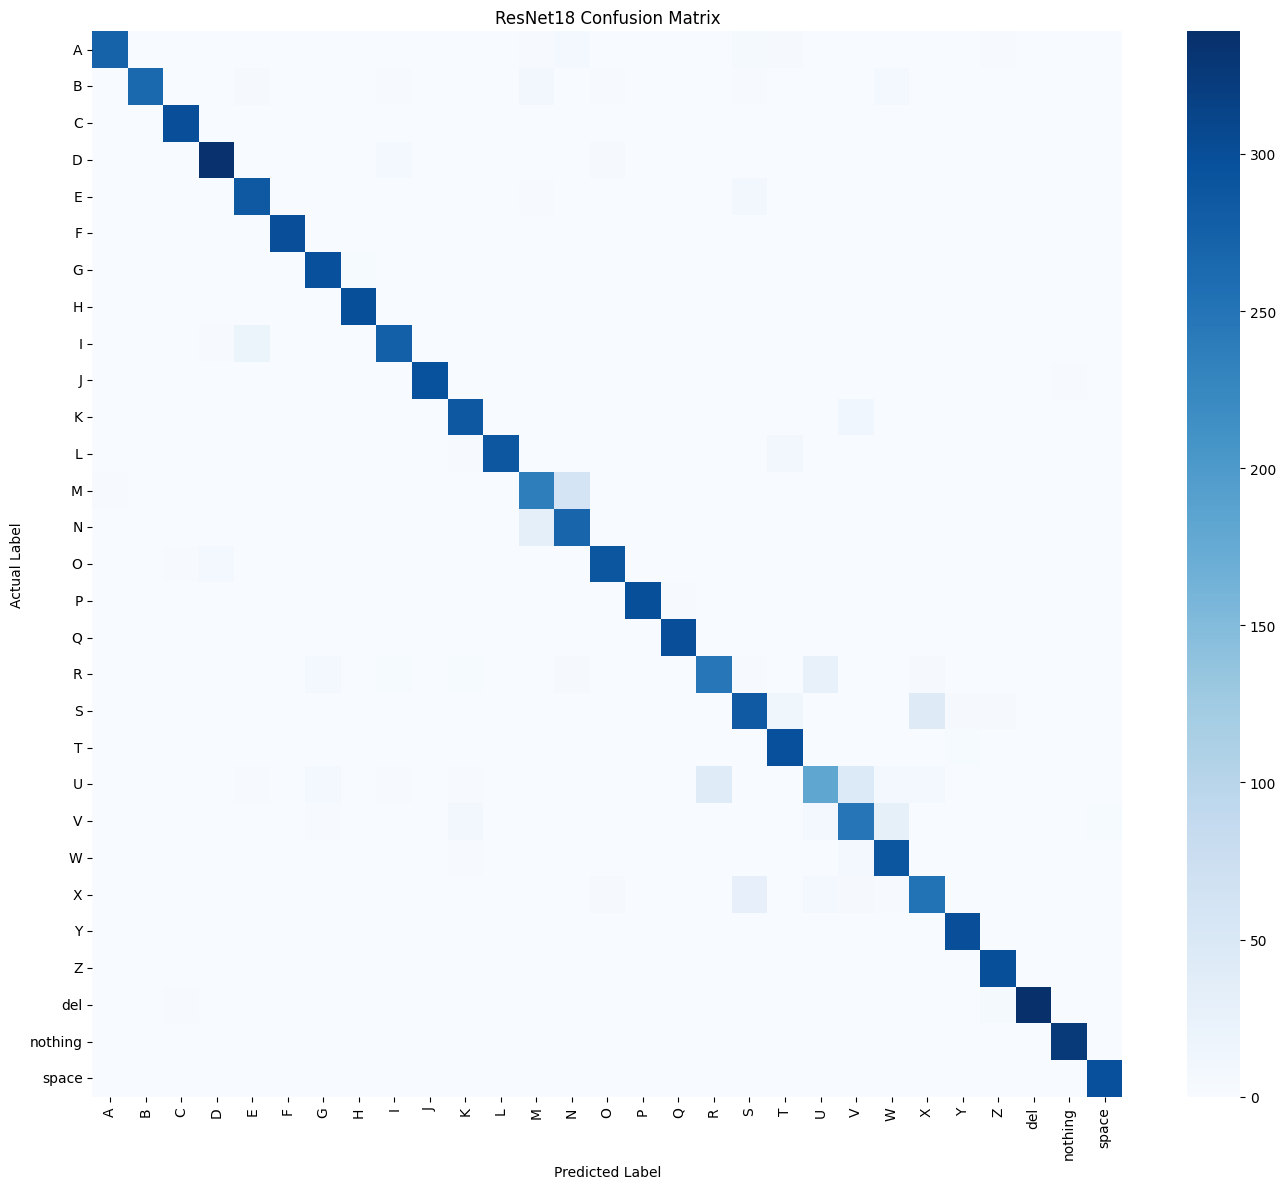

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

#class names in the same order as the dataset labels
class_names = (
    manifest[["y", "label"]]
    .drop_duplicates()
    .sort_values("y")["label"]
    .tolist()
)

#calculate confusion matrix
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names)))
)

#plot confusion matrix
plt.figure(figsize=(14, 12))
sns.heatmap(
    cm,
    annot=False,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("ResNet18 Confusion Matrix")
plt.tight_layout()
plt.show()

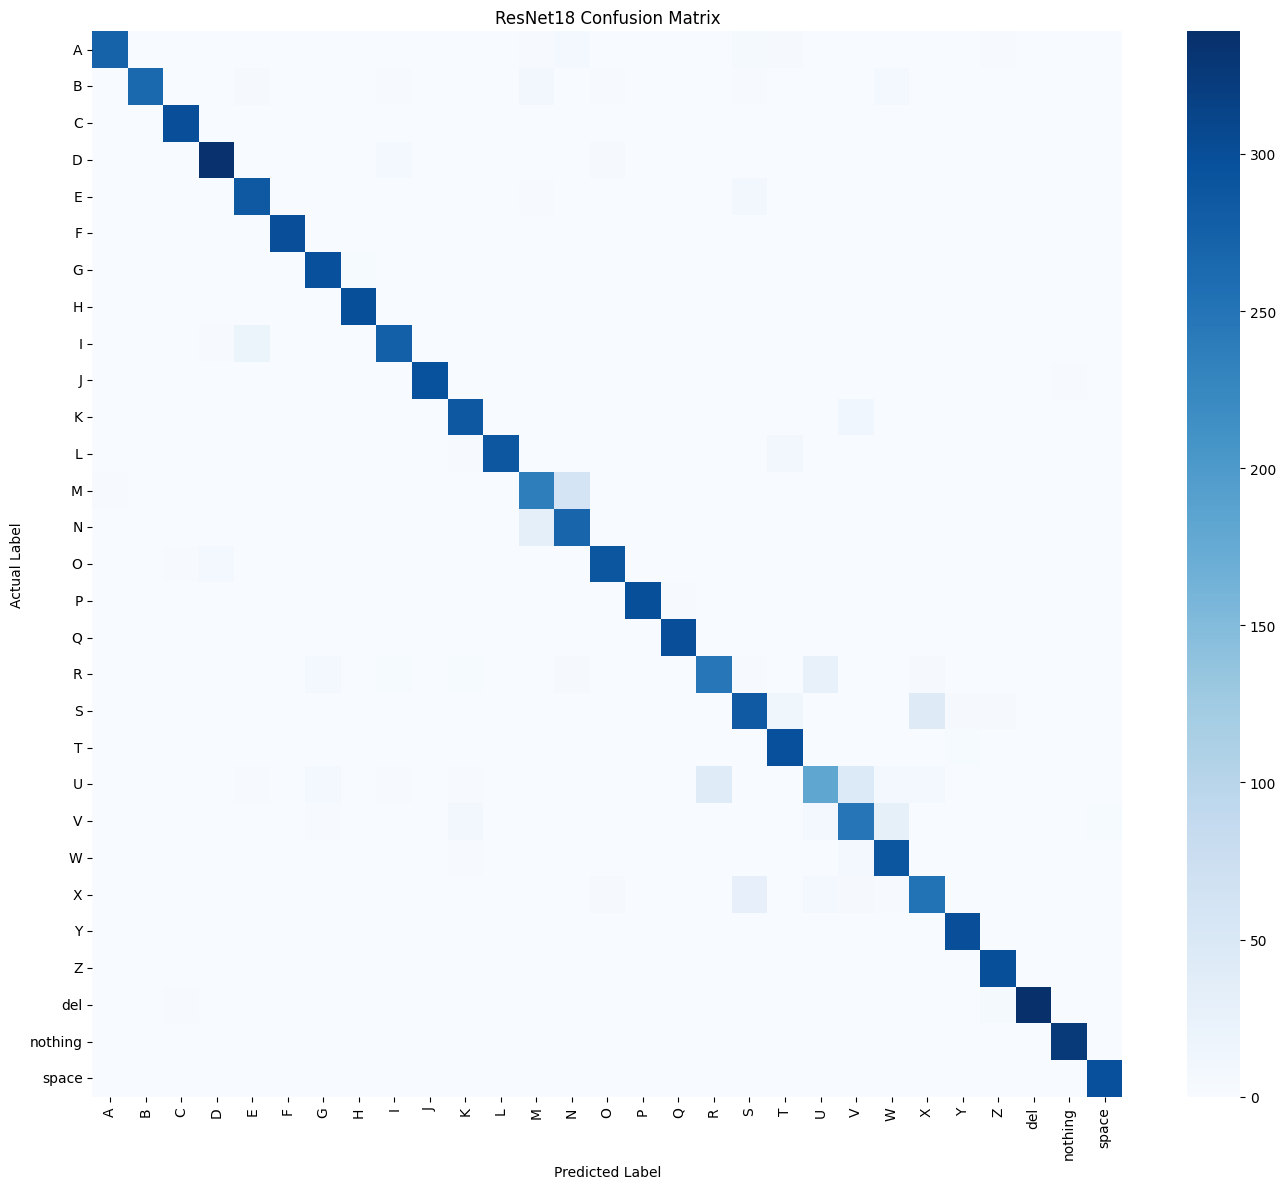

In [23]:
#save confusion matrix
plt.figure(figsize=(14, 12))

sns.heatmap(
    cm,
    annot=False,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("ResNet18 Confusion Matrix")
plt.tight_layout()

plt.savefig("resnet18_confusion_matrix.png", dpi=300)
plt.show()

MobileNetV3

In [25]:
from torchvision import models
from torch import nn

#load pretrained mobilenetv3
mobilenet = models.mobilenet_v3_small(
    weights=models.MobileNet_V3_Small_Weights.DEFAULT
)

#freeze pretrained layers
for param in mobilenet.parameters():
    param.requires_grad = False

#replace final layer for 29 asl classes
mobilenet.classifier[3] = nn.Linear(
    mobilenet.classifier[3].in_features,
    29
)

#move model to gpu
mobilenet = mobilenet.to(device)

print("MobileNetV3 loaded!")
print("Output classes:", mobilenet.classifier[3].out_features)
print("Device:", device)

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 143MB/s]

MobileNetV3 loaded!
Output classes: 29
Device: cuda


In [26]:
#setup mobilenet training
mobilenet_criterion = nn.CrossEntropyLoss()

mobilenet_optimizer = torch.optim.Adam(
    mobilenet.classifier[3].parameters(),
    lr=0.001
)

print("Loss function: CrossEntropyLoss")
print("Optimizer: Adam")
print("Learning rate: 0.001")
print("Training: final classification layer only")

Loss function: CrossEntropyLoss
Optimizer: Adam
Learning rate: 0.001
Training: final classification layer only


In [27]:
import time

#train mobilenet
epochs = 5
best_mobilenet_accuracy = 0
mobilenet_train_accuracies = []
mobilenet_val_accuracies = []

start_time = time.time()

for epoch in range(epochs):
    mobilenet.train()

    #keep frozen feature layers in evaluation mode
    mobilenet.features.eval()

    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        mobilenet_optimizer.zero_grad()

        outputs = mobilenet(images)
        loss = mobilenet_criterion(outputs, labels)

        loss.backward()
        mobilenet_optimizer.step()

        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_accuracy = train_correct / train_total
    mobilenet_train_accuracies.append(train_accuracy)

    #check validation accuracy
    mobilenet.eval()
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = mobilenet(images)

            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_accuracy = val_correct / val_total
    mobilenet_val_accuracies.append(val_accuracy)

    #save best model
    if val_accuracy > best_mobilenet_accuracy:
        best_mobilenet_accuracy = val_accuracy
        torch.save(
            mobilenet.state_dict(),
            "mobilenet_best.pth"
        )

    print(f"Epoch {epoch+1}/{epochs}")
    print(f"Training accuracy: {train_accuracy:.4f}")
    print(f"Validation accuracy: {val_accuracy:.4f}")
    print()

print("Training time:", round(time.time() - start_time, 2), "seconds")
print("Best validation accuracy:", round(best_mobilenet_accuracy, 4))

Epoch 1/5
Training accuracy: 0.7606
Validation accuracy: 0.7020

Epoch 2/5
Training accuracy: 0.9377
Validation accuracy: 0.7549

Epoch 3/5
Training accuracy: 0.9643
Validation accuracy: 0.7844

Epoch 4/5
Training accuracy: 0.9741
Validation accuracy: 0.8075

Epoch 5/5
Training accuracy: 0.9805
Validation accuracy: 0.8100

Training time: 294.5 seconds
Best validation accuracy: 0.81


In [28]:
#load best mobilenet model
mobilenet.load_state_dict(
    torch.load("mobilenet_best.pth", map_location=device)
)

#freeze all layers
for param in mobilenet.parameters():
    param.requires_grad = False

#unfreeze last feature blocks
for param in mobilenet.features[-3:].parameters():
    param.requires_grad = True

#unfreeze classifier
for param in mobilenet.classifier.parameters():
    param.requires_grad = True

#use smaller learning rate
mobilenet_optimizer = torch.optim.Adam(
    filter(lambda param: param.requires_grad, mobilenet.parameters()),
    lr=0.0001
)

print("Fine-tuning: last 3 feature blocks and classifier")
print("Learning rate: 0.0001")

Fine-tuning: last 3 feature blocks and classifier
Learning rate: 0.0001


In [29]:
import time

#fine-tune mobilenet
epochs = 5
best_mobilenet_finetuned_accuracy = 0
mobilenet_finetune_train_accuracies = []
mobilenet_finetune_val_accuracies = []

start_time = time.time()

for epoch in range(epochs):
    mobilenet.train()

    #keep frozen feature blocks in evaluation mode
    for block in mobilenet.features[:-3]:
        block.eval()

    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        mobilenet_optimizer.zero_grad()

        outputs = mobilenet(images)
        loss = mobilenet_criterion(outputs, labels)

        loss.backward()
        mobilenet_optimizer.step()

        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_accuracy = train_correct / train_total
    mobilenet_finetune_train_accuracies.append(train_accuracy)

    #check validation accuracy
    mobilenet.eval()
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = mobilenet(images)

            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_accuracy = val_correct / val_total
    mobilenet_finetune_val_accuracies.append(val_accuracy)

    #save best fine-tuned model
    if val_accuracy > best_mobilenet_finetuned_accuracy:
        best_mobilenet_finetuned_accuracy = val_accuracy
        torch.save(
            mobilenet.state_dict(),
            "mobilenet_finetuned_best.pth"
        )

    print(f"Epoch {epoch+1}/{epochs}")
    print(f"Training accuracy: {train_accuracy:.4f}")
    print(f"Validation accuracy: {val_accuracy:.4f}")
    print()

print("Fine-tuning time:", round(time.time() - start_time, 2), "seconds")
print("Best fine-tuned validation accuracy:", round(best_mobilenet_finetuned_accuracy, 4))

Epoch 1/5
Training accuracy: 0.9787
Validation accuracy: 0.9087

Epoch 2/5
Training accuracy: 0.9951
Validation accuracy: 0.9240

Epoch 3/5
Training accuracy: 0.9987
Validation accuracy: 0.9235

Epoch 4/5
Training accuracy: 0.9992
Validation accuracy: 0.9267

Epoch 5/5
Training accuracy: 0.9985
Validation accuracy: 0.9285

Fine-tuning time: 289.95 seconds
Best fine-tuned validation accuracy: 0.9285


In [30]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

#load best fine-tuned mobilenet
mobilenet.load_state_dict(
    torch.load("mobilenet_finetuned_best.pth", map_location=device)
)

mobilenet.eval()

#store predictions and actual labels
mobilenet_predictions = []
mobilenet_labels = []

#test mobilenet
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = mobilenet(images)
        predictions = outputs.argmax(dim=1)

        mobilenet_predictions.extend(predictions.cpu().numpy())
        mobilenet_labels.extend(labels.numpy())

#calculate metrics
mobilenet_accuracy = accuracy_score(mobilenet_labels, mobilenet_predictions)
mobilenet_precision = precision_score(mobilenet_labels, mobilenet_predictions, average="macro", zero_division=0)
mobilenet_recall = recall_score(mobilenet_labels, mobilenet_predictions, average="macro", zero_division=0)
mobilenet_f1 = f1_score(mobilenet_labels, mobilenet_predictions, average="macro", zero_division=0)

print(f"Test Accuracy: {mobilenet_accuracy:.4f}")
print(f"Precision: {mobilenet_precision:.4f}")
print(f"Recall: {mobilenet_recall:.4f}")
print(f"F1-score: {mobilenet_f1:.4f}")

Test Accuracy: 0.9316
Precision: 0.9327
Recall: 0.9322
F1-score: 0.9310


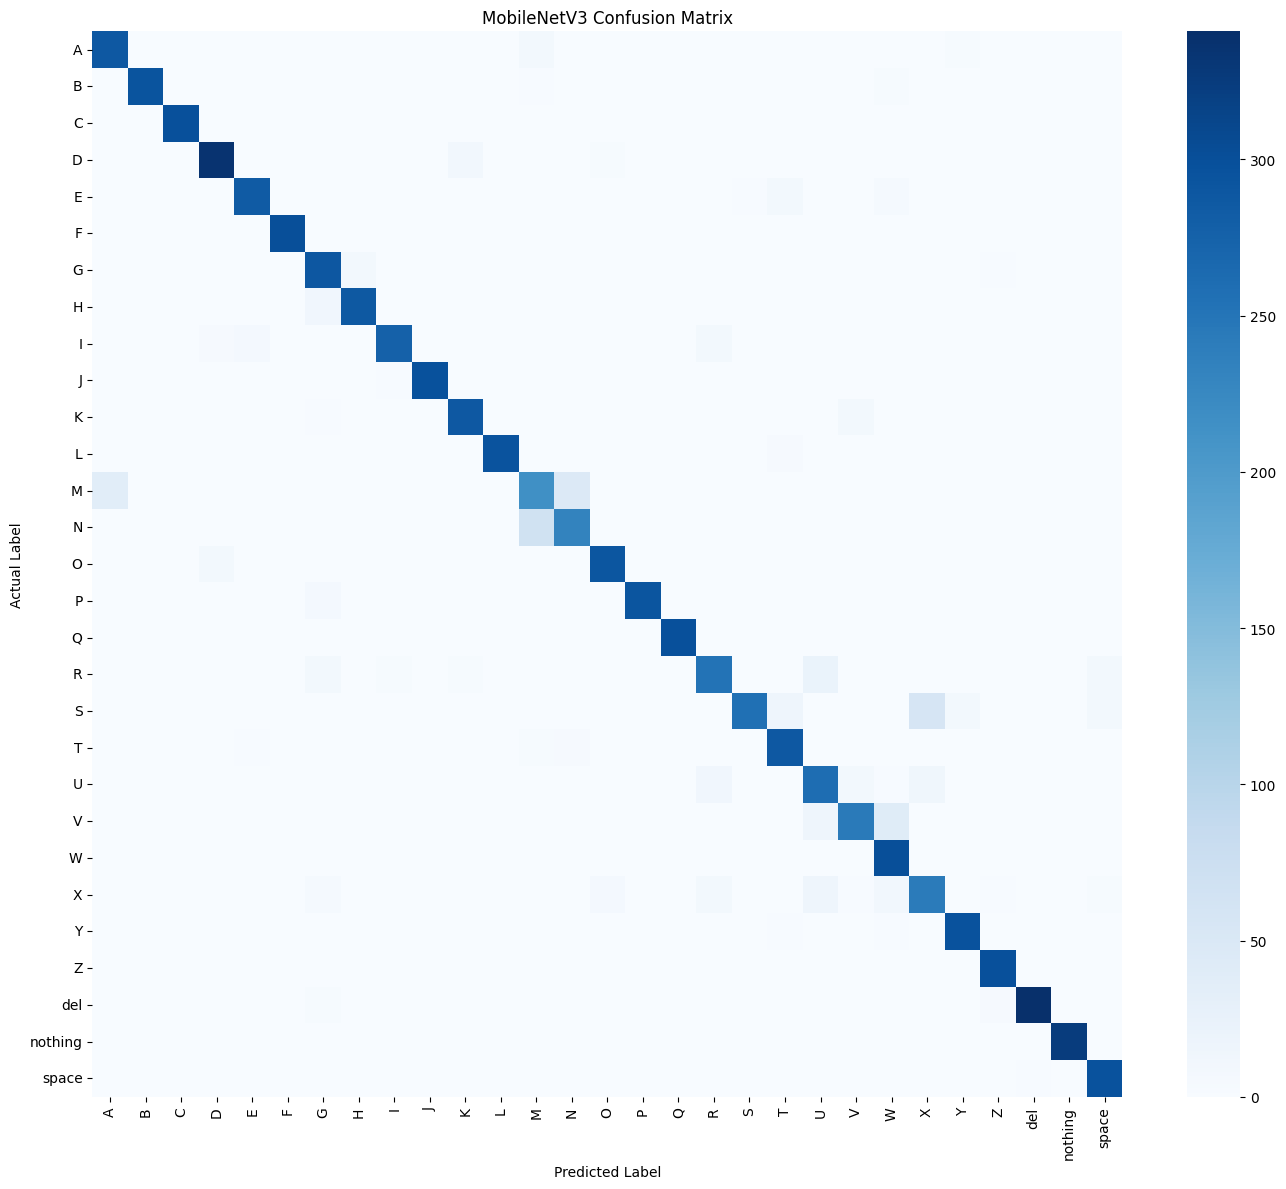

In [31]:
#mobilenet confusion matrix
mobilenet_cm = confusion_matrix(
    mobilenet_labels,
    mobilenet_predictions,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(14, 12))

sns.heatmap(
    mobilenet_cm,
    annot=False,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("MobileNetV3 Confusion Matrix")
plt.tight_layout()

#save image
plt.savefig("mobilenet_confusion_matrix.png", dpi=300)
plt.show()

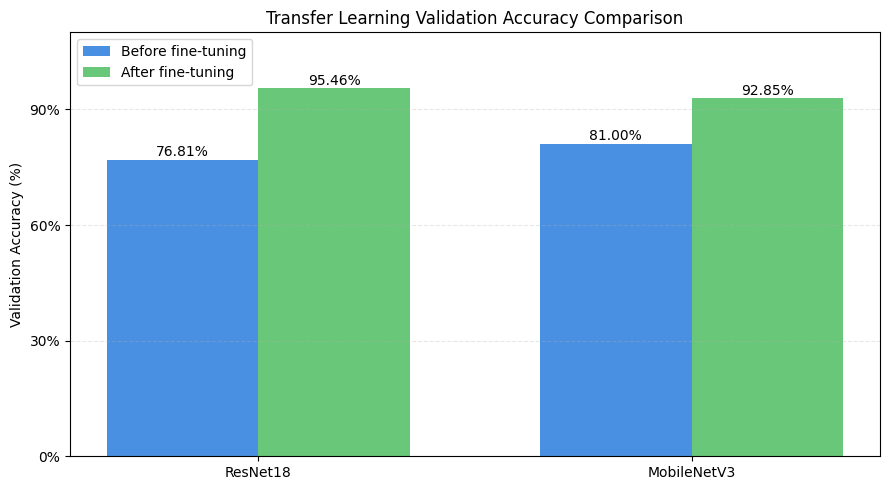

In [32]:
import matplotlib.pyplot as plt
import numpy as np

#validation accuracy results
models = ["ResNet18", "MobileNetV3"]
before = [76.81, 81.00]
after = [95.46, 92.85]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(9, 5))

#plot bars
plt.bar(x - width/2, before, width, label="Before fine-tuning", color="#4A90E2")
plt.bar(x + width/2, after, width, label="After fine-tuning", color="#69C779")

#chart labels
plt.title("Transfer Learning Validation Accuracy Comparison")
plt.ylabel("Validation Accuracy (%)")
plt.xticks(x, models)
plt.ylim(0, 110)
plt.yticks([0, 30, 60, 90], ["0%", "30%", "60%", "90%"])

#show percentages above bars
for i in range(len(models)):
    plt.text(x[i] - width/2, before[i] + 1, f"{before[i]:.2f}%", ha="center")
    plt.text(x[i] + width/2, after[i] + 1, f"{after[i]:.2f}%", ha="center")

plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()

#save chart
plt.savefig("transfer_learning_comparison.png", dpi=300)
plt.show()

In [33]:
import os

#model checkpoint sizes
resnet_size = os.path.getsize("resnet18_finetuned_best.pth") / (1024 * 1024)
mobilenet_size = os.path.getsize("mobilenet_finetuned_best.pth") / (1024 * 1024)

#number of model parameters
resnet_params = sum(p.numel() for p in model.parameters())
mobilenet_params = sum(p.numel() for p in mobilenet.parameters())

print("ResNet18:")
print(f"  Model size: {resnet_size:.2f} MB")
print(f"  Parameters: {resnet_params:,}")

print("\nMobileNetV3:")
print(f"  Model size: {mobilenet_size:.2f} MB")
print(f"  Parameters: {mobilenet_params:,}")

ResNet18:
  Model size: 42.77 MB
  Parameters: 11,191,389

MobileNetV3:
  Model size: 6.04 MB
  Parameters: 1,547,581


In [34]:
import time
import torch

#load best models
model.load_state_dict(
    torch.load("resnet18_finetuned_best.pth", map_location=device)
)

mobilenet.load_state_dict(
    torch.load("mobilenet_finetuned_best.pth", map_location=device)
)

model.eval()
mobilenet.eval()

#use the same image for both models
sample_image, _ = test_dataset[0]
sample_image = sample_image.unsqueeze(0).to(device)

def measure_speed(net, image, runs=100):
    #warm up gpu
    with torch.no_grad():
        for _ in range(10):
            net(image)

        torch.cuda.synchronize()

        start = time.perf_counter()

        for _ in range(runs):
            net(image)

        torch.cuda.synchronize()

    total_time = time.perf_counter() - start

    return (total_time / runs) * 1000

resnet_speed = measure_speed(model, sample_image)
mobilenet_speed = measure_speed(mobilenet, sample_image)

print(f"ResNet18: {resnet_speed:.2f} ms per image")
print(f"MobileNetV3: {mobilenet_speed:.2f} ms per image")

ResNet18: 6.08 ms per image
MobileNetV3: 15.05 ms per image


In [35]:
import pandas as pd

#save model comparison
comparison = pd.DataFrame({
    "Model": ["ResNet18", "MobileNetV3 Small"],
    "Test Accuracy": [0.9305, 0.9316],
    "Precision": [0.9309, 0.9327],
    "Recall": [0.9306, 0.9322],
    "F1 Score": [0.9296, 0.9310],
    "Model Size (MB)": [42.77, 6.04],
    "Parameters": [11191389, 1547581],
    "GPU Inference (ms/image)": [6.08, 15.05]
})

comparison.to_csv("transfer_learning_comparison.csv", index=False)

print(comparison.to_string(index=False))
print("\nSaved: transfer_learning_comparison.csv")

            Model  Test Accuracy  Precision  Recall  F1 Score  Model Size (MB)  Parameters  GPU Inference (ms/image)
         ResNet18         0.9305     0.9309  0.9306    0.9296            42.77    11191389                      6.08
MobileNetV3 Small         0.9316     0.9327  0.9322    0.9310             6.04     1547581                     15.05

Saved: transfer_learning_comparison.csv


In [37]:
import os

#check both photo folders
photo_folders = [
    "data/asl_photos_allie",
    "data/asl_photos_divya"
]

for folder in photo_folders:
    if os.path.exists(folder):
        print(f"\nFound: {folder}")
        print("Files:", os.listdir(folder))
    else:
        print(f"\nNot found: {folder}")


Found: data/asl_photos_allie
Files: ['O.png', 'M.png', 'G.png', 'T.png', 'I.png', 'P.png', 'R.png', 'B.png', 'Y.png', 'A.png', 'N.png', 'H.png', 'Q.png', 'S.png', 'V.png', 'L.png', 'C.png', 'D.png', 'W.png', 'U.png', 'K.png', 'F.png', 'E.png', 'X.png']

Found: data/asl_photos_divya
Files: ['L.jpg', 'Y.jpg', 'O.jpg', 'G.jpg', 'X.jpg', 'T.jpg', 'H.jpg', 'R.jpg', 'U.jpg', 'nothing.jpg', 'W.jpg', 'Z.jpg', 'S.jpg', 'P.jpg', 'K.jpg', 'Q.jpg', 'F.jpg', 'C.jpg', 'del.jpg', 'M.jpg', 'J.jpg', 'A.jpg', 'I.jpg', 'E.jpg', 'space.jpg', 'V.jpg', 'D.jpg', 'B.jpg', 'N.jpg']


In [38]:
from pathlib import Path
import pandas as pd

#collect our own asl photos
photo_data = []

folders = {
    "Allie": "data/asl_photos_allie",
    "Divya": "data/asl_photos_divya"
}

for person, folder in folders.items():
    for path in sorted(Path(folder).iterdir()):
        if path.suffix.lower() in [".png", ".jpg", ".jpeg"]:
            label = path.stem

            photo_data.append({
                "person": person,
                "path": str(path),
                "label": label
            })

photos_df = pd.DataFrame(photo_data)

print("Total photos:", len(photos_df))
print("\nPhotos per person:")
print(photos_df["person"].value_counts())

print("\nSample photos:")
print(photos_df.head())

Total photos: 53

Photos per person:
person
Divya    29
Allie    24
Name: count, dtype: int64

Sample photos:
  person                         path label
0  Allie  data/asl_photos_allie/A.png     A
1  Allie  data/asl_photos_allie/B.png     B
2  Allie  data/asl_photos_allie/C.png     C
3  Allie  data/asl_photos_allie/D.png     D
4  Allie  data/asl_photos_allie/E.png     E


In [41]:
#skip damaged photos
valid_photos = photos_df[~photos_df["path"].isin(bad_photos)]

results = []

for _, row in valid_photos.iterrows():
    #load image
    image = Image.open(row["path"]).convert("RGB")
    image = transform(image).unsqueeze(0).to(device)

    #make predictions
    with torch.no_grad():
        resnet_output = model(image)
        mobilenet_output = mobilenet(image)

    resnet_pred = class_names[resnet_output.argmax(1).item()]
    mobilenet_pred = class_names[mobilenet_output.argmax(1).item()]

    results.append({
        "person": row["person"],
        "actual": row["label"],
        "resnet_prediction": resnet_pred,
        "mobilenet_prediction": mobilenet_pred,
        "resnet_correct": resnet_pred.lower() == row["label"].lower(),
        "mobilenet_correct": mobilenet_pred.lower() == row["label"].lower()
    })

photo_results = pd.DataFrame(results)

#calculate accuracy
for person in ["Allie", "Divya"]:
    person_results = photo_results[photo_results["person"] == person]

    print(f"\n{person}:")
    print(f"ResNet18: {person_results['resnet_correct'].mean():.2%}")
    print(f"MobileNetV3: {person_results['mobilenet_correct'].mean():.2%}")

print("\nOverall:")
print(f"ResNet18: {photo_results['resnet_correct'].mean():.2%}")
print(f"MobileNetV3: {photo_results['mobilenet_correct'].mean():.2%}")


Allie:
ResNet18: 13.04%
MobileNetV3: 30.43%

Divya:
ResNet18: 13.79%
MobileNetV3: 31.03%

Overall:
ResNet18: 13.46%
MobileNetV3: 30.77%


In [42]:
#show incorrect predictions
wrong_predictions = photo_results[
    (~photo_results["resnet_correct"]) |
    (~photo_results["mobilenet_correct"])
]

print(wrong_predictions[
    ["person", "actual", "resnet_prediction", "mobilenet_prediction"]
].to_string(index=False))

person actual resnet_prediction mobilenet_prediction
 Allie      A                 N                    Z
 Allie      B                 E                    F
 Allie      C                 K                    C
 Allie      D                 I                    D
 Allie      F                 J                    H
 Allie      G                 B                space
 Allie      H           nothing                space
 Allie      I                 J                    D
 Allie      K           nothing                    I
 Allie      L                 L                    N
 Allie      M                 M                    I
 Allie      N                 M                    N
 Allie      O                 M                    F
 Allie      P           nothing                    Q
 Allie      Q                 N                    Q
 Allie      R                 I                    R
 Allie      S                 E                    N
 Allie      T                 E               

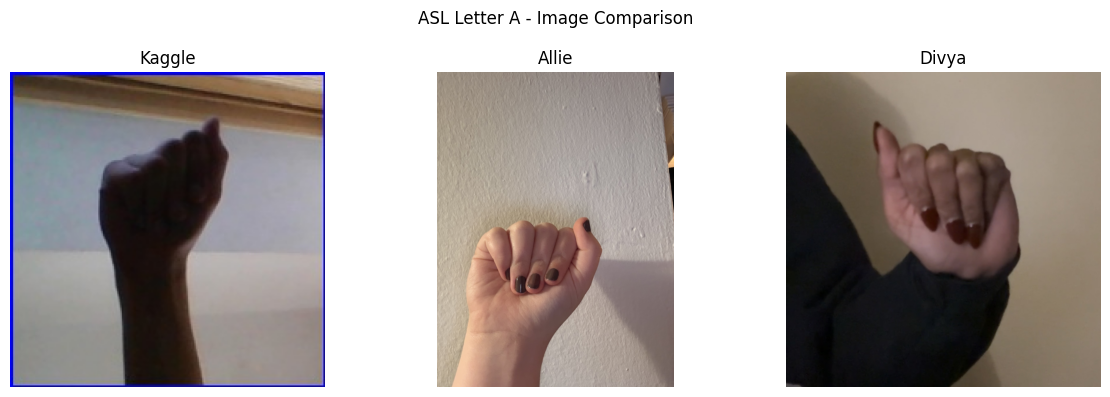

In [43]:
import matplotlib.pyplot as plt
from PIL import Image
import os

#compare the same letter from each source
letter = "A"

kaggle_path = os.path.join(data.TRAIN_DIR, f"{letter}/{letter}1.jpg")
allie_path = f"data/asl_photos_allie/{letter}.png"
divya_path = f"data/asl_photos_divya/{letter}.jpg"

paths = [kaggle_path, allie_path, divya_path]
titles = ["Kaggle", "Allie", "Divya"]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, path, title in zip(axes, paths, titles):
    image = Image.open(path).convert("RGB")
    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")

plt.suptitle("ASL Letter A - Image Comparison")
plt.tight_layout()
plt.show()

In [44]:
from PIL import Image

#compare original image dimensions
for path, title in zip(paths, titles):
    with Image.open(path) as img:
        print(f"{title}: {img.size}, mode: {img.mode}")

Kaggle: (200, 200), mode: RGB
Allie: (2316, 3088), mode: RGB
Divya: (1206, 1206), mode: RGB


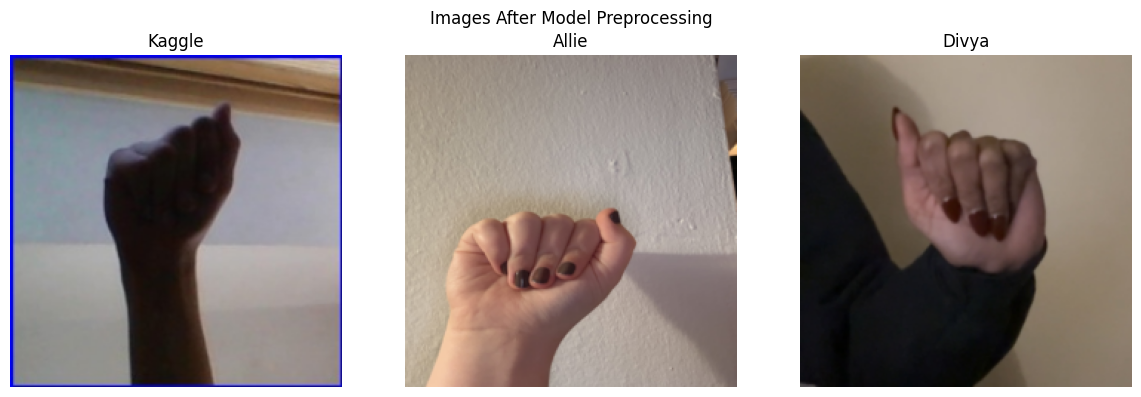

In [45]:
import matplotlib.pyplot as plt
import torch

#reverse imagenet normalization for display
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, path, title in zip(axes, paths, titles):
    image = Image.open(path).convert("RGB")

    #apply the same preprocessing used for testing
    processed = transform(image)

    #reverse normalization so we can display it
    display_image = processed.cpu() * std + mean
    display_image = display_image.clamp(0, 1)

    ax.imshow(display_image.permute(1, 2, 0))
    ax.set_title(title)
    ax.axis("off")

plt.suptitle("Images After Model Preprocessing")
plt.tight_layout()
plt.show()

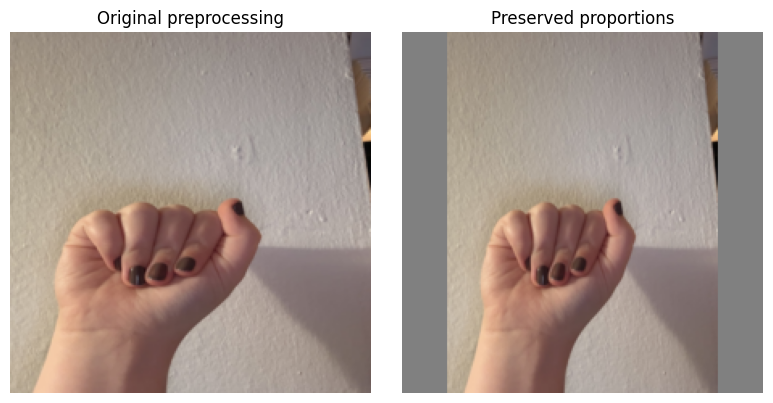

In [46]:
from PIL import ImageOps
from torchvision import transforms

#resize without stretching the hand
def resize_with_padding(image):
    return ImageOps.pad(
        image,
        (224, 224),
        method=Image.Resampling.BILINEAR,
        color=(128, 128, 128)
    )

#new preprocessing for personal photos
padded_transform = transforms.Compose([
    transforms.Lambda(resize_with_padding),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

#compare original and padded preprocessing
image = Image.open("data/asl_photos_allie/A.png").convert("RGB")

original = transform(image)
padded = padded_transform(image)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

for ax, img, title in zip(
    axes,
    [original, padded],
    ["Original preprocessing", "Preserved proportions"]
):
    display_img = (img.cpu() * std + mean).clamp(0, 1)
    ax.imshow(display_img.permute(1, 2, 0))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [47]:
#test models with padded preprocessing
padded_results = []

model.eval()
mobilenet.eval()

for _, row in valid_photos.iterrows():
    image = Image.open(row["path"]).convert("RGB")
    image = padded_transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        resnet_pred = class_names[model(image).argmax(1).item()]
        mobilenet_pred = class_names[mobilenet(image).argmax(1).item()]

    padded_results.append({
        "person": row["person"],
        "actual": row["label"],
        "resnet_correct": resnet_pred.lower() == row["label"].lower(),
        "mobilenet_correct": mobilenet_pred.lower() == row["label"].lower()
    })

padded_results = pd.DataFrame(padded_results)

#compare accuracy before and after padding
print("Original preprocessing:")
print(f"ResNet18: {photo_results['resnet_correct'].mean():.2%}")
print(f"MobileNetV3: {photo_results['mobilenet_correct'].mean():.2%}")

print("\nPadded preprocessing:")
print(f"ResNet18: {padded_results['resnet_correct'].mean():.2%}")
print(f"MobileNetV3: {padded_results['mobilenet_correct'].mean():.2%}")

print("\nAccuracy by person:")
for person in ["Allie", "Divya"]:
    subset = padded_results[padded_results["person"] == person]
    print(f"{person}: ResNet18 {subset['resnet_correct'].mean():.2%}, "
          f"MobileNetV3 {subset['mobilenet_correct'].mean():.2%}")

Original preprocessing:
ResNet18: 13.46%
MobileNetV3: 30.77%

Padded preprocessing:
ResNet18: 21.15%
MobileNetV3: 30.77%

Accuracy by person:
Allie: ResNet18 30.43%, MobileNetV3 30.43%
Divya: ResNet18 13.79%, MobileNetV3 31.03%


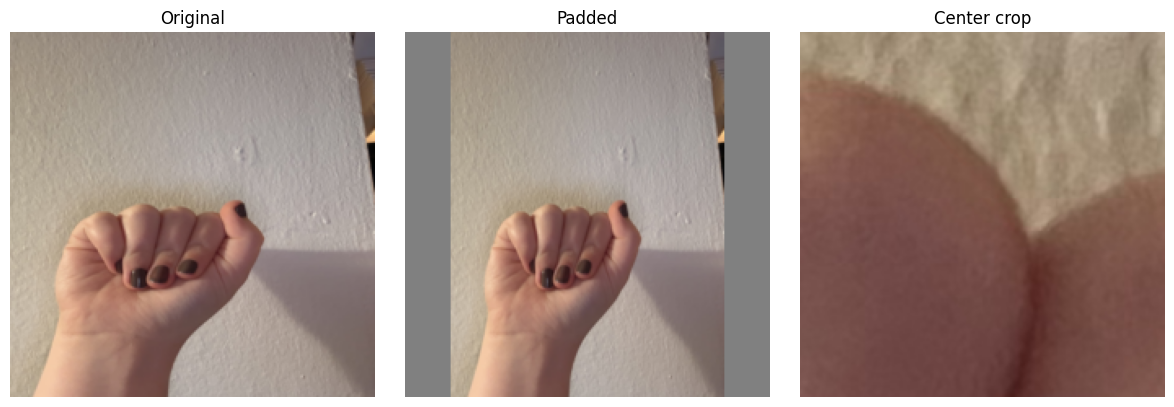

In [48]:
from torchvision import transforms

#crop the center of the image
crop_transform = transforms.Compose([
    transforms.CenterCrop(180),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

#compare preprocessing methods
image = Image.open("data/asl_photos_allie/A.png").convert("RGB")

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, img, title in zip(
    axes,
    [transform(image), padded_transform(image), crop_transform(image)],
    ["Original", "Padded", "Center crop"]
):
    display_img = (img.cpu() * std + mean).clamp(0, 1)
    ax.imshow(display_img.permute(1, 2, 0))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

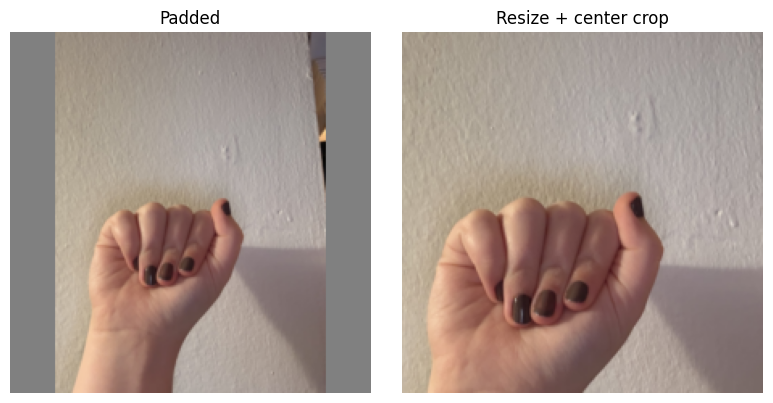

In [49]:
#resize first, then crop
better_crop_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

#compare padded and cropped images
image = Image.open("data/asl_photos_allie/A.png").convert("RGB")

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

for ax, img, title in zip(
    axes,
    [padded_transform(image), better_crop_transform(image)],
    ["Padded", "Resize + center crop"]
):
    display_img = (img.cpu() * std + mean).clamp(0, 1)
    ax.imshow(display_img.permute(1, 2, 0))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [50]:
#test models with resize and center crop
crop_results = []

model.eval()
mobilenet.eval()

for _, row in valid_photos.iterrows():
    image = Image.open(row["path"]).convert("RGB")
    image = better_crop_transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        resnet_pred = class_names[model(image).argmax(1).item()]
        mobilenet_pred = class_names[mobilenet(image).argmax(1).item()]

    crop_results.append({
        "person": row["person"],
        "actual": row["label"],
        "resnet_correct": resnet_pred.lower() == row["label"].lower(),
        "mobilenet_correct": mobilenet_pred.lower() == row["label"].lower()
    })

crop_results = pd.DataFrame(crop_results)

#compare all three preprocessing methods
print("                   ResNet18    MobileNetV3")
print(f"Original:          {photo_results['resnet_correct'].mean():.2%}      {photo_results['mobilenet_correct'].mean():.2%}")
print(f"Padded:            {padded_results['resnet_correct'].mean():.2%}      {padded_results['mobilenet_correct'].mean():.2%}")
print(f"Resize + crop:     {crop_results['resnet_correct'].mean():.2%}      {crop_results['mobilenet_correct'].mean():.2%}")

print("\nAccuracy by person (resize + crop):")
for person in ["Allie", "Divya"]:
    subset = crop_results[crop_results["person"] == person]
    print(f"{person}: ResNet18 {subset['resnet_correct'].mean():.2%}, "
          f"MobileNetV3 {subset['mobilenet_correct'].mean():.2%}")

                   ResNet18    MobileNetV3
Original:          13.46%      30.77%
Padded:            21.15%      30.77%
Resize + crop:     13.46%      19.23%

Accuracy by person (resize + crop):
Allie: ResNet18 17.39%, MobileNetV3 13.04%
Divya: ResNet18 10.34%, MobileNetV3 24.14%


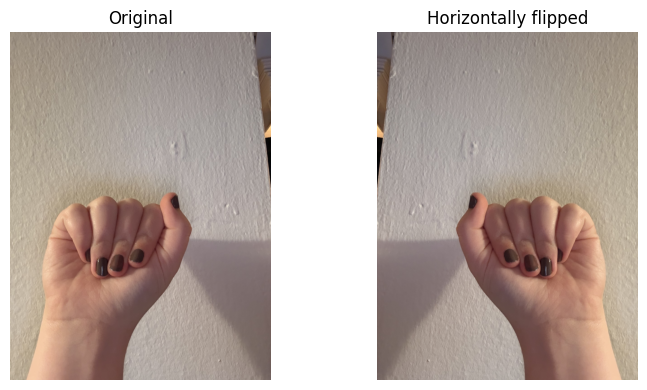

In [51]:
from PIL import Image, ImageOps
import matplotlib.pyplot as plt

#compare normal and flipped image
image = Image.open("data/asl_photos_allie/A.png").convert("RGB")
flipped = ImageOps.mirror(image)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(image)
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(flipped)
axes[1].set_title("Horizontally flipped")
axes[1].axis("off")

plt.tight_layout()
plt.show()


In [52]:
from PIL import ImageOps

#test horizontally flipped photos
flipped_results = []

model.eval()
mobilenet.eval()

for _, row in valid_photos.iterrows():
    image = Image.open(row["path"]).convert("RGB")

    #flip image horizontally
    image = ImageOps.mirror(image)

    #apply padded preprocessing
    image = padded_transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        resnet_pred = class_names[model(image).argmax(1).item()]
        mobilenet_pred = class_names[mobilenet(image).argmax(1).item()]

    flipped_results.append({
        "person": row["person"],
        "actual": row["label"],
        "resnet_correct": resnet_pred.lower() == row["label"].lower(),
        "mobilenet_correct": mobilenet_pred.lower() == row["label"].lower()
    })

flipped_results = pd.DataFrame(flipped_results)

print("                   ResNet18    MobileNetV3")
print(f"Original:          {photo_results['resnet_correct'].mean():.2%}      {photo_results['mobilenet_correct'].mean():.2%}")
print(f"Padded:            {padded_results['resnet_correct'].mean():.2%}      {padded_results['mobilenet_correct'].mean():.2%}")
print(f"Flipped + padded:  {flipped_results['resnet_correct'].mean():.2%}      {flipped_results['mobilenet_correct'].mean():.2%}")

print("\nAccuracy by person (flipped + padded):")
for person in ["Allie", "Divya"]:
    subset = flipped_results[flipped_results["person"] == person]
    print(f"{person}: ResNet18 {subset['resnet_correct'].mean():.2%}, "
          f"MobileNetV3 {subset['mobilenet_correct'].mean():.2%}")

                   ResNet18    MobileNetV3
Original:          13.46%      30.77%
Padded:            21.15%      30.77%
Flipped + padded:  21.15%      26.92%

Accuracy by person (flipped + padded):
Allie: ResNet18 21.74%, MobileNetV3 26.09%
Divya: ResNet18 20.69%, MobileNetV3 27.59%


In [53]:
#save preprocessing comparison
preprocessing_comparison = pd.DataFrame({
    "Preprocessing": [
        "Original",
        "Padded",
        "Resize + center crop",
        "Flipped + padded"
    ],
    "ResNet18 Accuracy": [
        0.1346, 0.2115, 0.1346, 0.2115
    ],
    "MobileNetV3 Accuracy": [
        0.3077, 0.3077, 0.1923, 0.2692
    ]
})

preprocessing_comparison.to_csv(
    "personal_photos_preprocessing_comparison.csv",
    index=False
)

print(preprocessing_comparison.to_string(index=False))
print("\nSaved: personal_photos_preprocessing_comparison.csv")

       Preprocessing  ResNet18 Accuracy  MobileNetV3 Accuracy
            Original             0.1346                0.3077
              Padded             0.2115                0.3077
Resize + center crop             0.1346                0.1923
    Flipped + padded             0.2115                0.2692

Saved: personal_photos_preprocessing_comparison.csv


In [54]:
from torchvision import transforms

#add variation to training images
augmented_transform = transforms.Compose([
    transforms.RandomRotation(15),
    transforms.RandomAffine(
        degrees=0,
        translate=(0.1, 0.1),
        scale=(0.9, 1.1)
    ),
    transforms.ColorJitter(
        brightness=0.3,
        contrast=0.3,
        saturation=0.2
    ),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

#use the same kaggle training images
augmented_train_dataset = ASLDataset(
    manifest[
        (manifest["split"] == "train") &
        (manifest["subset10k"] == True)
    ],
    data.TRAIN_DIR,
    augmented_transform
)

augmented_train_loader = DataLoader(
    augmented_train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2
)

print("Augmented training images:", len(augmented_train_dataset))

Augmented training images: 10005


In [55]:
import torch
import torch.nn as nn
from torchvision import models

#load pretrained mobilenetv3
augmented_mobilenet = models.mobilenet_v3_small(
    weights=models.MobileNet_V3_Small_Weights.DEFAULT
)

#freeze the pretrained layers
for param in augmented_mobilenet.parameters():
    param.requires_grad = False

#replace the classifier for 29 asl classes
num_features = augmented_mobilenet.classifier[3].in_features
augmented_mobilenet.classifier[3] = nn.Linear(num_features, 29)

#move model to gpu
augmented_mobilenet = augmented_mobilenet.to(device)

#setup optimizer and loss
augmented_criterion = nn.CrossEntropyLoss()

augmented_optimizer = torch.optim.Adam(
    augmented_mobilenet.classifier[3].parameters(),
    lr=0.001
)

print("Augmented MobileNetV3 ready!")
print("Device:", device)
print("Training images:", len(augmented_train_dataset))

Augmented MobileNetV3 ready!
Device: cuda
Training images: 10005


In [ ]:
import time
import copy

#train augmented mobilenet classifier
best_val_acc = 0
best_weights = None

start_time = time.time()

for epoch in range(5):
    augmented_mobilenet.train()

    #keep pretrained layers frozen
    augmented_mobilenet.features.eval()

    train_correct = 0
    train_total = 0

    for images, labels in augmented_train_loader:
        images = images.to(device)
        labels = labels.to(device)

        augmented_optimizer.zero_grad()

        outputs = augmented_mobilenet(images)
        loss = augmented_criterion(outputs, labels)

        loss.backward()
        augmented_optimizer.step()

        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_acc = train_correct / train_total

    #check validation accuracy
    augmented_mobilenet.eval()

    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = augmented_mobilenet(images)

            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_acc = val_correct / val_total

    print(f"Epoch {epoch+1}/5 - Train: {train_acc:.4f}, Val: {val_acc:.4f}")

    #save best model
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_weights = copy.deepcopy(augmented_mobilenet.state_dict())

#save best checkpoint
augmented_mobilenet.load_state_dict(best_weights)
torch.save(best_weights, "mobilenet_augmented_best.pth")

print(f"\nBest validation accuracy: {best_val_acc:.4f}")
print(f"Training time: {time.time() - start_time:.2f} seconds")
print("Saved: mobilenet_augmented_best.pth")


Epoch 1/5 - Train: 0.7110, Val: 0.6518
Epoch 2/5 - Train: 0.8894, Val: 0.7054
Epoch 3/5 - Train: 0.9141, Val: 0.7379
Epoch 4/5 - Train: 0.9291, Val: 0.7513
